In [17]:
import pandas as pd

url = "https://raw.githubusercontent.com/owid/energy-data/master/owid-energy-data.csv"

df = pd.read_csv(url)

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("Latest year:", df["year"].max())

df.head()

Rows: 23377
Columns: 130
Latest year: 2025


,country,year,iso_code,population,gdp,biofuel_cons_change_pct,biofuel_cons_change_twh,biofuel_cons_per_capita,biofuel_consumption,biofuel_elec_per_capita,...,solar_share_elec,solar_share_energy,wind_cons_change_pct,wind_cons_change_twh,wind_consumption,wind_elec_per_capita,wind_electricity,wind_energy_per_capita,wind_share_elec,wind_share_energy
0,ASEAN (Ember),2000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN
1,ASEAN (Ember),2001,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN
2,ASEAN (Ember),2002,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN
3,ASEAN (Ember),2003,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN
4,ASEAN (Ember),2004,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN


In [18]:
features = [
    "country",
    "year",
    "iso_code",
    "renewables_share_elec",
    "solar_share_elec",
    "wind_share_elec",
    "hydro_share_elec",
    "electricity_demand",
    "gdp",
    "population"
]

print("Available columns:")
print([col for col in features if col in df.columns])

print("\nMissing values:")
print(df[[col for col in features if col in df.columns]]
      .isnull().sum())

Available columns:
['country', 'year', 'iso_code', 'renewables_share_elec', 'solar_share_elec', 'wind_share_elec', 'hydro_share_elec', 'electricity_demand', 'gdp', 'population']

Missing values:
country                      0
year                         0
iso_code                  6112
renewables_share_elec    15505
solar_share_elec         15508
wind_share_elec          15716
hydro_share_elec         15600
electricity_demand       16999
gdp                      11597
population                4483
dtype: int64


In [19]:
# Step 3: Data Cleaning & Preparation

import pandas as pd

# Select relevant features
columns = [
    "country",
    "year",
    "iso_code",
    "renewables_share_elec",
    "solar_share_elec",
    "wind_share_elec",
    "hydro_share_elec",
    "electricity_demand",
    "gdp",
    "population"
]

energy = df[columns].copy()

# Keep individual countries and recent years
energy = energy[
    (energy["iso_code"].str.fullmatch(r"[A-Z]{3}", na=False)) &
    (energy["year"].between(2015, 2025))
].copy()

# Remove rows missing our main target
energy = energy.dropna(subset=["renewables_share_elec"])

# Remove duplicate country-year records
energy = energy.drop_duplicates(
    subset=["country", "year"]
)

# Sort data chronologically
energy = energy.sort_values(
    ["country", "year"]
).reset_index(drop=True)

print("Cleaned rows:", energy.shape[0])
print("Countries:", energy["country"].nunique())
print("Year range:", energy["year"].min(), "-", energy["year"].max())

print("\nMissing values after cleaning:")
print(energy.isnull().sum())

energy.head()

Cleaned rows: 2191
Countries: 212
Year range: 2015 - 2025

Missing values after cleaning:
country                    0
year                       0
iso_code                   0
renewables_share_elec      0
solar_share_elec           0
wind_share_elec           38
hydro_share_elec          35
electricity_demand         0
gdp                      871
population                 0
dtype: int64


,country,year,iso_code,renewables_share_elec,solar_share_elec,wind_share_elec,hydro_share_elec,electricity_demand,gdp,population
0,Afghanistan,2015,AFG,87.288,2.542,0.0,84.746,4.96,6.278339e+10,33831767.0
1,Afghanistan,2016,AFG,87.603,3.306,0.0,84.298,5.54,6.437222e+10,34700613.0
2,Afghanistan,2017,AFG,86.508,3.175,0.0,83.333,5.87,6.516928e+10,35688941.0
3,Afghanistan,2018,AFG,82.906,3.419,0.0,79.487,6.16,6.599674e+10,36743040.0
4,Afghanistan,2019,AFG,87.671,4.110,0.0,83.562,6.37,7.308570e+10,37856125.0


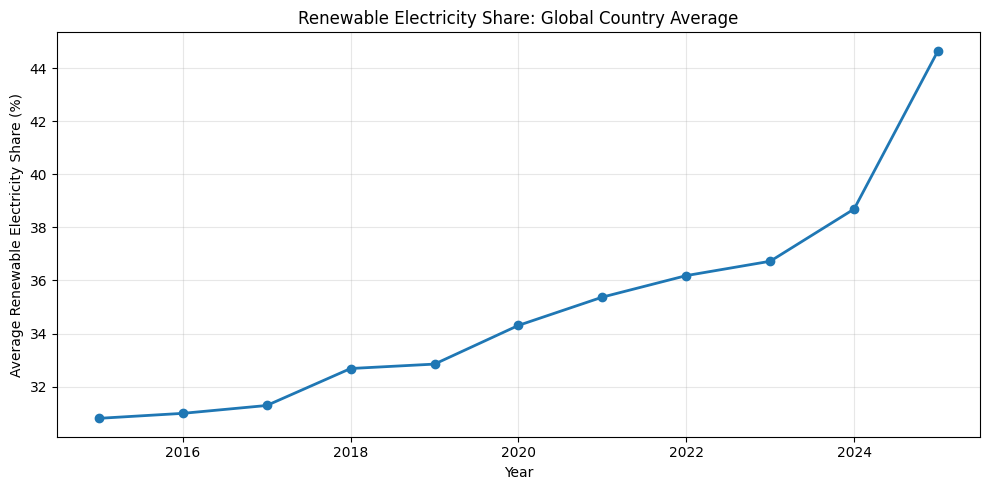

Average in 2015: 30.8 %
Average in 2025: 44.65 %


In [20]:
import matplotlib.pyplot as plt

# Global renewable electricity trend
global_trend = (
    energy.groupby("year")["renewables_share_elec"]
    .mean()
)

plt.figure(figsize=(10, 5))

plt.plot(
    global_trend.index,
    global_trend.values,
    marker="o",
    linewidth=2
)

plt.title("Renewable Electricity Share: Global Country Average")
plt.xlabel("Year")
plt.ylabel("Average Renewable Electricity Share (%)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Average in 2015:", round(global_trend.loc[2015], 2), "%")
print("Average in 2025:", round(global_trend.loc[2025], 2), "%")

Countries analyzed: 207
Optimal clusters: 5
Silhouette score: 0.501

Cluster profiles:
         solar_share_elec  wind_share_elec  hydro_share_elec
cluster                                                     
0                    3.45             1.58              8.08
1                   13.77            18.43             16.50
2                    2.32             1.45             74.24
3                   22.30             2.54             12.70
4                    7.12            39.00              7.19


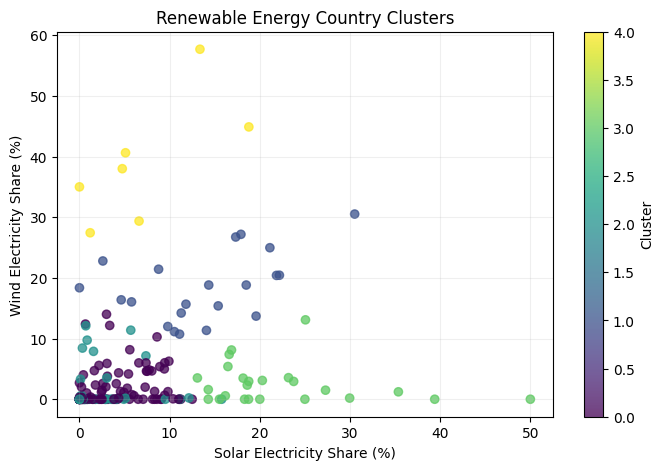

In [21]:
# Step 5: Renewable Energy Clustering

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

# Latest available observation per country
latest = (
    energy.sort_values("year")
    .groupby("country")
    .tail(1)
    .copy()
)

cluster_features = [
    "solar_share_elec",
    "wind_share_elec",
    "hydro_share_elec"
]

# Keep countries with complete feature values
cluster_data = latest.dropna(
    subset=cluster_features
).copy()

X = cluster_data[cluster_features]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Compare possible numbers of clusters
scores = {}

for k in range(2, 7):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    labels = model.fit_predict(X_scaled)
    scores[k] = silhouette_score(X_scaled, labels)

best_k = max(scores, key=scores.get)

final_model = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

cluster_data["cluster"] = final_model.fit_predict(X_scaled)

print("Countries analyzed:", len(cluster_data))
print("Optimal clusters:", best_k)
print("Silhouette score:", round(scores[best_k], 3))

print("\nCluster profiles:")
print(
    cluster_data.groupby("cluster")[cluster_features]
    .mean().round(2)
)

plt.figure(figsize=(8, 5))
plt.scatter(
    cluster_data["solar_share_elec"],
    cluster_data["wind_share_elec"],
    c=cluster_data["cluster"],
    cmap="viridis",
    alpha=0.75
)
plt.xlabel("Solar Electricity Share (%)")
plt.ylabel("Wind Electricity Share (%)")
plt.title("Renewable Energy Country Clusters")
plt.colorbar(label="Cluster")
plt.grid(alpha=0.2)
plt.show()

In [22]:
# Check the observation years used in clustering

print("Observation years in clustering:")
print(cluster_data["year"].value_counts().sort_index())

print("\nYear range:")
print(
    cluster_data["year"].min(),
    "to",
    cluster_data["year"].max()
)

Observation years in clustering:
year
2022      2
2023     14
2024    103
2025     88
Name: count, dtype: int64

Year range:
2022 to 2025


Clustering Methodology Note

Country-level clustering was conducted using the latest available observation for each country, based on solar, wind, and hydropower electricity shares. The analysis includes 207 countries, with observations spanning 2022–2025.

Because reporting years differ across countries, the resulting clusters represent the latest available renewable electricity profiles rather than a strictly synchronized cross-sectional comparison. This limitation is considered when interpreting the findings.

In [23]:
# Step 6: Predictive Machine Learning

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

model_data = energy.sort_values(["country", "year"]).copy()

grouped = model_data.groupby("country")

model_data["previous_share"] = grouped["renewables_share_elec"].shift(1)
model_data["previous_year"] = grouped["year"].shift(1)

model_data["next_share"] = grouped["renewables_share_elec"].shift(-1)
model_data["next_year"] = grouped["year"].shift(-1)

# Require both neighboring observations to be consecutive years
model_data = model_data.loc[
    (model_data["previous_year"] == model_data["year"] - 1) &
    (model_data["next_year"] == model_data["year"] + 1)
].copy()

features_ml = [
    "renewables_share_elec",
    "previous_share",
    "solar_share_elec",
    "wind_share_elec",
    "hydro_share_elec"
]

model_data = model_data.dropna(
    subset=features_ml + ["next_share"]
)

train = model_data.loc[model_data["next_year"] <= 2023].copy()
test = model_data.loc[model_data["next_year"] >= 2024].copy()

X_train = train[features_ml]
y_train = train["next_share"]

X_test = test[features_ml]
y_test = test["next_share"]

model = RandomForestRegressor(
    n_estimators=100,
    max_depth=10,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

predictions = model.predict(X_test)
baseline = test["renewables_share_elec"]

print("Training records:", len(train))
print("Testing records:", len(test))
print("Baseline MAE:", round(mean_absolute_error(y_test, baseline), 3))
print("Random Forest MAE:", round(mean_absolute_error(y_test, predictions), 3))
print("Random Forest R2:", round(r2_score(y_test, predictions), 3))

Training records: 1439
Testing records: 279
Baseline MAE: 1.965
Random Forest MAE: 2.144
Random Forest R2: 0.989


In [24]:
print("Training target years:")
print(sorted(train["next_year"].unique()))

print("\nTesting target years:")
print(sorted(test["next_year"].unique()))

print("\nMissing values in training features:")
print(X_train.isna().sum())

print("\nMissing values in testing features:")
print(X_test.isna().sum())

print("\nTarget overlap:")
print(
    set(train["next_year"].unique())
    & set(test["next_year"].unique())
)

Training target years:
[np.float64(2017.0), np.float64(2018.0), np.float64(2019.0), np.float64(2020.0), np.float64(2021.0), np.float64(2022.0), np.float64(2023.0)]

Testing target years:
[np.float64(2024.0), np.float64(2025.0)]

Missing values in training features:
renewables_share_elec    0
previous_share           0
solar_share_elec         0
wind_share_elec          0
hydro_share_elec         0
dtype: int64

Missing values in testing features:
renewables_share_elec    0
previous_share           0
solar_share_elec         0
wind_share_elec          0
hydro_share_elec         0
dtype: int64

Target overlap:
set()


In [25]:
# Step 7: Compare a second ML model

from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, r2_score

boosting_model = HistGradientBoostingRegressor(
    max_iter=150,
    learning_rate=0.05,
    max_leaf_nodes=15,
    l2_regularization=1.0,
    random_state=42
)

boosting_model.fit(X_train, y_train)

boosting_predictions = boosting_model.predict(X_test)

results = pd.DataFrame({
    "Model": [
        "Baseline",
        "Random Forest",
        "Gradient Boosting"
    ],
    "MAE": [
        mean_absolute_error(y_test, baseline),
        mean_absolute_error(y_test, predictions),
        mean_absolute_error(y_test, boosting_predictions)
    ]
})

print(results.round(3))
print(
    "\nGradient Boosting R2:",
    round(r2_score(y_test, boosting_predictions), 3)
)

               Model    MAE
0           Baseline  1.965
1      Random Forest  2.144
2  Gradient Boosting  2.159

Gradient Boosting R2: 0.989


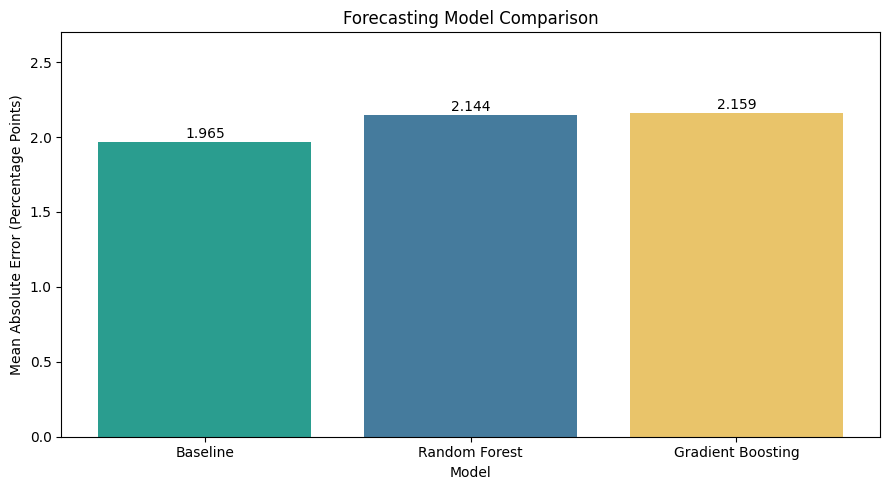

In [26]:
# Step 8: Model Performance Comparison

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

bars = plt.bar(
    results["Model"],
    results["MAE"],
    color=["#2A9D8F", "#457B9D", "#E9C46A"]
)

plt.title("Forecasting Model Comparison")
plt.ylabel("Mean Absolute Error (Percentage Points)")
plt.xlabel("Model")
plt.ylim(0, results["MAE"].max() * 1.25)

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.03,
        f"{bar.get_height():.3f}",
        ha="center"
    )

plt.tight_layout()
plt.savefig("model_comparison.png", dpi=300)
plt.show()

In [27]:
# Step 9: Temporal Consistency Audit

check = energy.sort_values(
    ["country", "year"]
).copy()

check["previous_year"] = (
    check.groupby("country")["year"].shift(1)
)

check["next_year"] = (
    check.groupby("country")["year"].shift(-1)
)

has_previous = check["previous_year"].notna()
has_next = check["next_year"].notna()

consecutive = (
    check["previous_year"].eq(check["year"] - 1)
    & check["next_year"].eq(check["year"] + 1)
)

year_gap = (
    (has_previous & check["previous_year"].ne(check["year"] - 1))
    | (has_next & check["next_year"].ne(check["year"] + 1))
)

print("Total cleaned rows:", len(check))
print("Rows with consecutive neighboring years:", int(consecutive.sum()))
print("Rows with detected year gaps:", int(year_gap.sum()))
print("Rows used for modeling:", len(model_data))
print(
    "All modeled rows have consecutive neighbors:",
    bool(consecutive.loc[model_data.index].all())
)

Total cleaned rows: 2191
Rows with consecutive neighboring years: 1767
Rows with detected year gaps: 0
Rows used for modeling: 1718
All modeled rows have consecutive neighbors: True


In [28]:
# Step 10: Final Model Validation

import pandas as pd
from sklearn.metrics import mean_absolute_error

print("=== FINAL MODEL VALIDATION ===")

# Verify that training and testing target years do not overlap
train_years = set(train["next_year"].astype(int))
test_years = set(test["next_year"].astype(int))

print("Training target years:", sorted(train_years))
print("Testing target years:", sorted(test_years))
print("Target year overlap:", sorted(train_years & test_years))

# Verify that the target is not used as a model input
print("Target excluded from features:", "next_share" not in X_train.columns)

# Verify that features contain no missing values
print("Missing training features:", int(X_train.isna().sum().sum()))
print("Missing testing features:", int(X_test.isna().sum().sum()))

# Recalculate performance
validation = pd.DataFrame({
    "Model": ["Persistence Baseline", "Random Forest", "Gradient Boosting"],
    "MAE": [
        mean_absolute_error(y_test, baseline),
        mean_absolute_error(y_test, predictions),
        mean_absolute_error(y_test, boosting_predictions)
    ]
}).sort_values("MAE")

print("\nModel performance:")
print(validation.to_string(index=False))

print("\nBest model:", validation.iloc[0]["Model"])

assert not (train_years & test_years), "Training and testing target years overlap!"
assert "next_share" not in X_train.columns, "Target leakage detected!"
assert X_train.notna().all().all(), "Missing training features!"
assert X_test.notna().all().all(), "Missing testing features!"

print("\nBasic validation checks passed.")

=== FINAL MODEL VALIDATION ===
Training target years: [2017, 2018, 2019, 2020, 2021, 2022, 2023]
Testing target years: [2024, 2025]
Target year overlap: []
Target excluded from features: True
Missing training features: 0
Missing testing features: 0

Model performance:
               Model      MAE
Persistence Baseline 1.965000
       Random Forest 2.144341
   Gradient Boosting 2.158797

Best model: Persistence Baseline

Basic validation checks passed.


Random Forest Feature Importance:
renewables_share_elec    0.9840
previous_share           0.0075
wind_share_elec          0.0033
hydro_share_elec         0.0026
solar_share_elec         0.0025
dtype: float64


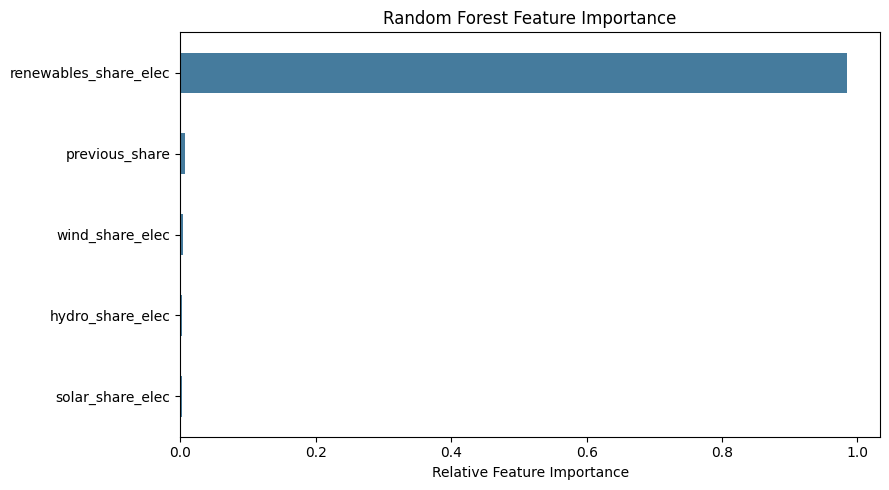

In [29]:
# Step 11: Model Interpretability

import pandas as pd
import matplotlib.pyplot as plt

importance = pd.Series(
    model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=True)

print("Random Forest Feature Importance:")
print(importance.sort_values(ascending=False).round(4))

plt.figure(figsize=(9, 5))
importance.plot(kind="barh", color="#457B9D")
plt.title("Random Forest Feature Importance")
plt.xlabel("Relative Feature Importance")
plt.tight_layout()
plt.show()

In [30]:
# Step 12: Country-Level Error Analysis

evaluation = test[["country", "next_year"]].copy()

evaluation["actual"] = y_test
evaluation["baseline_prediction"] = baseline
evaluation["rf_prediction"] = predictions

evaluation["baseline_error"] = abs(
    evaluation["actual"] - evaluation["baseline_prediction"]
)

evaluation["rf_error"] = abs(
    evaluation["actual"] - evaluation["rf_prediction"]
)

country_errors = (
    evaluation.groupby("country")
    .agg(
        observations=("actual", "size"),
        baseline_mae=("baseline_error", "mean"),
        rf_mae=("rf_error", "mean")
    )
)

country_errors["rf_improvement"] = (
    country_errors["baseline_mae"] - country_errors["rf_mae"]
)

print("Countries evaluated:", len(country_errors))

print("\nCountries where Random Forest performs better:")
print((country_errors["rf_improvement"] > 0).sum())

print("\nCountries where Baseline performs better:")
print((country_errors["rf_improvement"] < 0).sum())

print("\nCountries with highest Random Forest errors:")
print(
    country_errors.sort_values(
        "rf_mae", ascending=False
    ).head(10).round(3)
)

Countries evaluated: 191

Countries where Random Forest performs better:
84

Countries where Baseline performs better:
107

Countries with highest Random Forest errors:
                 observations  baseline_mae  rf_mae  rf_improvement
country                                                            
Nauru                       1        20.000  18.847           1.153
Colombia                    2        10.666   8.729           1.937
Macao                       1         2.564   8.518          -5.954
Lebanon                     1         9.744   8.096           1.648
Montenegro                  2         8.744   8.050           0.695
Chile                       2         5.284   7.816          -2.532
North Macedonia             2         7.569   6.508           1.061
Venezuela                   1         0.797   6.474          -5.677
Liberia                     1         2.991   6.352          -3.361
Sri Lanka                   2         6.528   6.343           0.185


In [31]:
# Step 13: Year-by-Year Forecast Evaluation

yearly_eval = test[["country", "next_year"]].copy()

yearly_eval["actual"] = y_test
yearly_eval["baseline_prediction"] = baseline
yearly_eval["rf_prediction"] = predictions
yearly_eval["gb_prediction"] = boosting_predictions

from sklearn.metrics import mean_absolute_error

yearly_results = []

for year, group in yearly_eval.groupby("next_year"):
    yearly_results.append({
        "Year": int(year),
        "Observations": len(group),
        "Baseline MAE": mean_absolute_error(
            group["actual"], group["baseline_prediction"]
        ),
        "Random Forest MAE": mean_absolute_error(
            group["actual"], group["rf_prediction"]
        ),
        "Gradient Boosting MAE": mean_absolute_error(
            group["actual"], group["gb_prediction"]
        )
    })

yearly_results = pd.DataFrame(yearly_results)

print("Year-by-Year Forecast Evaluation:")
print(yearly_results.round(3).to_string(index=False))

print("\nBest-performing model by year:")
for _, row in yearly_results.iterrows():
    scores = {
        "Persistence Baseline": row["Baseline MAE"],
        "Random Forest": row["Random Forest MAE"],
        "Gradient Boosting": row["Gradient Boosting MAE"]
    }
    print(f"{int(row['Year'])}: {min(scores, key=scores.get)}")

Year-by-Year Forecast Evaluation:
 Year  Observations  Baseline MAE  Random Forest MAE  Gradient Boosting MAE
 2024           191         1.767              1.938                  1.897
 2025            88         2.395              2.592                  2.728

Best-performing model by year:
2024: Persistence Baseline
2025: Persistence Baseline


In [32]:
# Step 14: Cluster Interpretation

cluster_features = [
    "solar_share_elec",
    "wind_share_elec",
    "hydro_share_elec"
]

cluster_summary = (
    cluster_data
    .groupby("cluster")[cluster_features]
    .agg(["mean", "median"])
    .round(2)
)

cluster_sizes = (
    cluster_data.groupby("cluster")
    .size()
    .rename("countries")
)

print("Countries per cluster:")
print(cluster_sizes.to_string())

print("\nRenewable energy profiles by cluster:")
print(cluster_summary.to_string())

print("\nObservation years by cluster:")
print(
    pd.crosstab(
        cluster_data["cluster"],
        cluster_data["year"]
    ).to_string()
)

Countries per cluster:
cluster
0    110
1     21
2     45
3     24
4      7

Renewable energy profiles by cluster:
        solar_share_elec        wind_share_elec        hydro_share_elec       
                    mean median            mean median             mean median
cluster                                                                       
0                   3.45   2.47            1.58   0.00             8.08   1.96
1                  13.77  14.08           18.43  18.37            16.50  11.37
2                   2.32   0.70            1.45   0.00            74.24  75.76
3                  22.30  18.76            2.54   1.54            12.70   3.62
4                   7.12   5.11           39.00  38.00             7.19   2.10

Observation years by cluster:
year     2022  2023  2024  2025
cluster                        
0           1    12    60    37
1           0     1     1    19
2           1     1    29    14
3           0     0    12    12
4           0     0     1     